# Autonomous Parking Area Detection with YOLO

This notebook detects a rectangular tape parking area with a one-class YOLO model and interprets its image-space geometry. Motor control, navigation, ArUco, and LiDAR are intentionally excluded.

Dataset: `/home/ayskopi/autonomous_parking/parking_area_yolo_dataset`
Class: `parking_area`

## 1. Project Introduction and Objectives

Pipeline: Camera/Image -> Image Preprocessing -> YOLO Detection -> Bounding Box -> Confidence -> Center/Width/Height/Orientation -> Target Parking Position -> Basic Decision Logic.

The notebook inspects the supplied dataset, visualizes annotations, trains and evaluates a lightweight detector, runs unseen test inference, interprets detections, and provides a real-world test log.

## 1.1 Overall System Architecture

The system is organized as a vision-only perception pipeline. Camera images are prepared and passed to a YOLOv8n detector. The detected bounding box is then interpreted in image coordinates to estimate the parking-area center and basic geometry. Validation and test outputs are used to assess detector performance.

```mermaid
flowchart LR
    A[ORBBEC Astra Pro Camera<br/>Captured Image] --> B[Image Dataset<br/>Train / Validation / Test]
    B --> C[Image Preprocessing<br/>Resize and Letterbox]
    C --> D[YOLOv8n Training<br/>Parking Area Class]
    D --> E[Trained Best Model<br/>best.pt]
    E --> F[YOLO Inference]
    F --> G{Parking Area Detected?}
    G -->|No| H[No Detection<br/>Failure Case]
    G -->|Yes| I[Bounding Box and Confidence]
    I --> J[Parking Area Interpretation]
    J --> K[Center x,y<br/>Width and Height<br/>Relative Position<br/>Approx. Orientation]
    K --> L[Image-Space Target<br/>Detected-Area Center]

    E --> M[Validation and Test Evaluation]
    M --> N[Precision, Recall<br/>mAP and Confidence]
    F --> O[Prediction Visualizations<br/>Successful and Unsuccessful Cases]

    L -. Future extension .-> P[Navigation and Motor Control<br/>Not implemented]
```

The current implementation ends at image-space interpretation. It does not perform camera calibration, metric pose estimation, path planning, navigation, or motor control.

In [1]:
#Install dataset and visualization dependencies first.
%pip install -q --retries 20 --resume-retries 20 --timeout 120 pyyaml pandas matplotlib seaborn pillow opencv-python

# This project uses CPU by default. Install CPU-only PyTorch explicitly so pip does
# not try to resolve a larger CUDA build on machines without a CUDA requirement.
%pip install -q --retries 20 --resume-retries 20 --timeout 120 torch torchvision --index-url https://download.pytorch.org/whl/cpu

# Install Ultralytics after PyTorch is available.
%pip install -q --retries 20 --resume-retries 20 --timeout 120 ultralytics
print('Installation finished. Restart the kernel, then rerun the imports cell before training.')

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Installation finished. Restart the kernel, then rerun the imports cell before training.


In [2]:
from pathlib import Path
import importlib.util, math, random, sys, subprocess

# Repair missing lightweight imports in the active notebook environment.
required_packages = {
    'yaml': 'pyyaml',
    'cv2': 'opencv-python',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'seaborn': 'seaborn',
    'PIL': 'pillow',
}
missing_packages = [package for module, package in required_packages.items() if importlib.util.find_spec(module) is None]
if missing_packages:
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '--retries', '20',
        '--resume-retries', '20', '--timeout', '120', *missing_packages
    ])

import yaml
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

try:
    from ultralytics import YOLO
except ModuleNotFoundError:
    YOLO = None
    print('Ultralytics/PyTorch is not available yet. Dataset inspection can run; rerun the setup cell before training.')

SEED=42; random.seed(SEED); np.random.seed(SEED)
DATASET_DIR=Path('/home/c-jaylavapie/cv/autonomous_parking/parking_area_yolo_dataset')
RUNS_DIR=Path('/home/c-jaylavapie/cv/autonomous_parking/parking_area_runs'); RUNS_DIR.mkdir(exist_ok=True)
DATA_YAML=DATASET_DIR/'data.yaml'; IMAGE_EXTENSIONS={'.jpg','.jpeg','.png','.bmp','.webp'}
CONFIDENCE_THRESHOLD=0.50; IMG_SIZE=640
print(DATASET_DIR.exists(), DATA_YAML)

True /home/c-jaylavapie/cv/autonomous_parking/parking_area_yolo_dataset/data.yaml


## 2. Dataset Loading and Inspection

Class names and split definitions are read from `data.yaml`; the local dataset path is used without changing the original YAML or image files.

In [3]:
with DATA_YAML.open() as stream: config=yaml.safe_load(stream)
names=config.get('names',{}); CLASS_NAMES={i:n for i,n in enumerate(names)} if isinstance(names,list) else {int(i):n for i,n in names.items()}
NUM_CLASSES=int(config.get('nc',len(CLASS_NAMES)))
SPLITS={'Training':'train','Validation':'valid','Testing':'test'}
def image_files(folder): return sorted(p for p in Path(folder).iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
def inspect_split(split):
    images=image_files(DATASET_DIR/split/'images'); labels=list((DATASET_DIR/split/'labels').glob('*.txt'))
    dims=sorted({Image.open(p).size for p in images})
    return {'Images':len(images),'Annotation files':len(labels),'Image dimensions':', '.join(f'{w}x{h}' for w,h in dims),'Image-label pairs':sum((DATASET_DIR/split/'labels'/f'{p.stem}.txt').exists() for p in images)}
inspection=pd.DataFrame({k:inspect_split(v) for k,v in SPLITS.items()}).T
display(inspection); print('Classes:',NUM_CLASSES,CLASS_NAMES)

,Images,Annotation files,Image dimensions,Image-label pairs
Training,280,280,640x480,280
Validation,80,80,640x480,80
Testing,40,40,640x480,40


Classes: 1 {0: 'parking_area'}


## 3. Dataset Visualization

YOLO labels are normalized `(class_id, center_x, center_y, width, height)`. The samples below show bounding-box annotations converted to pixels.

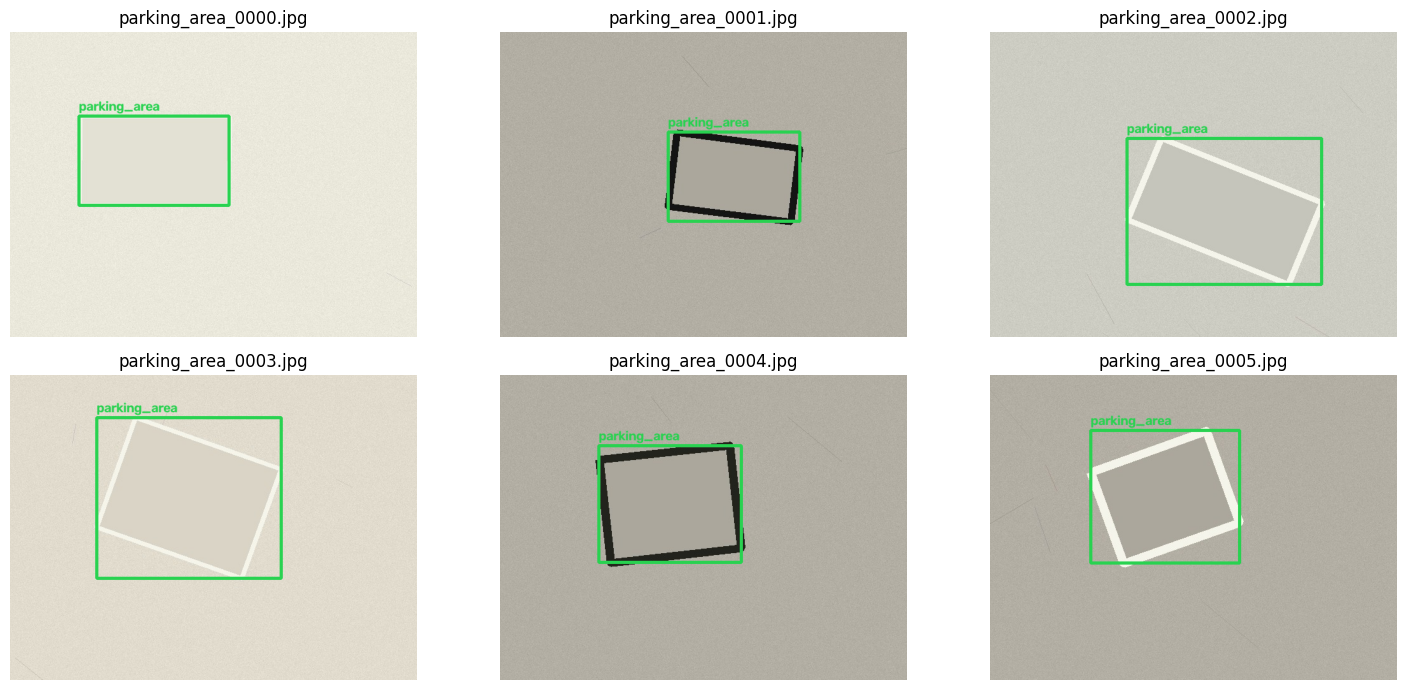

In [4]:
def read_labels(path):
    return [[int(v[0]),*map(float,v[1:])] for v in (line.split() for line in path.read_text().splitlines()) if len(v)==5] if path.exists() else []
def annotated(path):
    image=cv2.cvtColor(cv2.imread(str(path)),cv2.COLOR_BGR2RGB); h,w=image.shape[:2]
    for cls,cx,cy,bw,bh in read_labels(DATASET_DIR/'train'/'labels'/f'{path.stem}.txt'):
        x1,y1,x2,y2=int((cx-bw/2)*w),int((cy-bh/2)*h),int((cx+bw/2)*w),int((cy+bh/2)*h)
        cv2.rectangle(image,(x1,y1),(x2,y2),(40,210,80),3); cv2.putText(image,CLASS_NAMES[cls],(x1,max(20,y1-8)),0,0.7,(40,210,80),2)
    return image
paths=image_files(DATASET_DIR/'train'/'images')[:6]; fig,axes=plt.subplots(2,3,figsize=(15,7))
for ax,path in zip(axes.ravel(),paths): ax.imshow(annotated(path)); ax.set_title(path.name); ax.axis('off')
plt.tight_layout(); plt.show()

## 4. Image Preprocessing

Ultralytics handles letterboxing/resizing, tensor conversion, normalization, and training augmentation. This preview demonstrates a non-destructive 640x640 letterbox. Training uses small rotation/translation/scale, horizontal flip, and HSV augmentation.

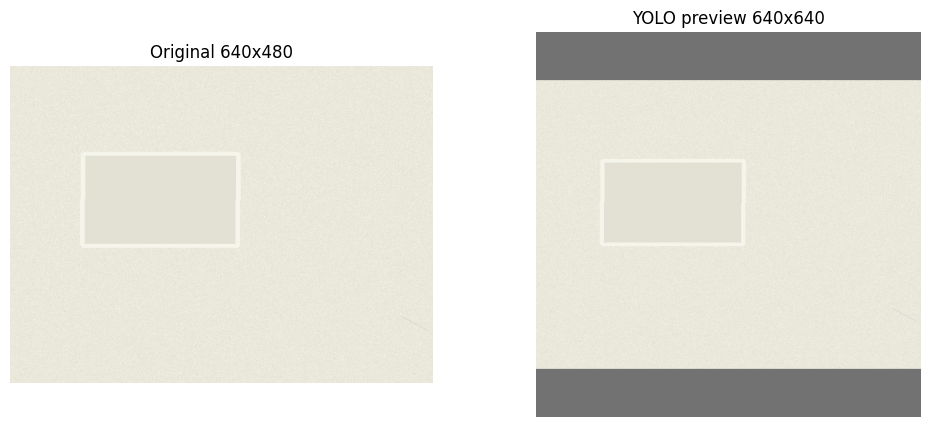

In [5]:
def letterbox(image,size=IMG_SIZE):
    h,w=image.shape[:2]; scale=min(size/w,size/h); nw,nh=round(w*scale),round(h*scale); resized=cv2.resize(image,(nw,nh)); px,py=(size-nw)//2,(size-nh)//2
    return cv2.copyMakeBorder(resized,py,size-nh-py,px,size-nw-px,cv2.BORDER_CONSTANT,value=(114,114,114))
sample=cv2.cvtColor(cv2.imread(str(paths[0])),cv2.COLOR_BGR2RGB); processed=letterbox(sample)
fig,ax=plt.subplots(1,2,figsize=(12,5)); ax[0].imshow(sample); ax[0].set_title('Original 640x480'); ax[1].imshow(processed); ax[1].set_title('YOLO preview 640x640'); [a.axis('off') for a in ax]; plt.show()

## 5. YOLO Model Configuration and Training


In [6]:
MODEL_NAME='yolov8n.pt'; EPOCHS=50; BATCH_SIZE=16; LEARNING_RATE=0.01
try:
    import torch
    DEVICE=0 if torch.cuda.is_available() else 'cpu'
except ModuleNotFoundError:
    torch=None
    DEVICE='cpu'
    print('PyTorch is not installed. Configuration and dataset cells can run on CPU; install Ultralytics before training.')
local_config=dict(config); local_config.update(path=str(DATASET_DIR),train='train/images',val='valid/images',test='test/images')
LOCAL_DATA_YAML=RUNS_DIR/'data_local.yaml'; yaml.safe_dump(local_config,LOCAL_DATA_YAML.open('w'),sort_keys=False)
display(pd.DataFrame({'Setting':['YOLO model','Input size','Classes','Epochs','Batch size','Learning rate','Device','Dataset path'],'Value':[MODEL_NAME,IMG_SIZE,NUM_CLASSES,EPOCHS,BATCH_SIZE,LEARNING_RATE,DEVICE,str(DATASET_DIR)]}))

,Setting,Value
0,YOLO model,yolov8n.pt
1,Input size,640
2,Classes,1
3,Epochs,50
4,Batch size,16
5,Learning rate,0.01
6,Device,0
7,Dataset path,/home/c-jaylavapie/cv/autonomous_parking/parki...


In [7]:
if YOLO is None:
    raise RuntimeError('Ultralytics/PyTorch is unavailable. Rerun the setup cell, complete the ultralytics installation, restart the kernel, and rerun the imports cell before training.')
model=YOLO(MODEL_NAME)
model.train(data=str(LOCAL_DATA_YAML),imgsz=IMG_SIZE,epochs=EPOCHS,batch=BATCH_SIZE,lr0=LEARNING_RATE,device=DEVICE,project=str(RUNS_DIR),name='yolo_training',exist_ok=True,plots=True,degrees=5,translate=.1,scale=.2,fliplr=.5,hsv_h=.015,hsv_s=.5,hsv_v=.3)
BEST_WEIGHTS=RUNS_DIR/'yolo_training'/'weights'/'best.pt'

Ultralytics 8.4.183 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX A5000, 24112MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/c-jaylavapie/cv/autonomous_parking/parking_area_runs/data_local.yaml, degrees=5, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_trai

## 6. Training Results and Model Evaluation

Training writes `results.csv`, result graphs, PR/F1 curves, and a confusion matrix under `parking_area_runs/yolo_training`. Precision measures correct predictions among predictions; recall measures detected actual areas; mAP summarizes detection performance; confidence describes an individual detection.

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
45,46,129.305,0.28188,0.16642,0.80214,0.99934,1.0,0.995,0.92652,0.39057,0.18854,0.83327,0.000218,0.000218,0.000218
46,47,131.897,0.26120,0.16755,0.80816,0.99933,1.0,0.995,0.91311,0.46381,0.19814,0.86193,0.000178,0.000178,0.000178
47,48,134.424,0.26395,0.16317,0.80474,1.00000,1.0,0.995,0.91589,0.45081,0.19882,0.86791,0.000139,0.000139,0.000139
48,49,136.769,0.28108,0.16829,0.81409,1.00000,1.0,0.995,0.93897,0.35119,0.17860,0.83223,0.000099,0.000099,0.000099
49,50,139.341,0.25651,0.15977,0.79333,1.00000,1.0,0.995,0.92720,0.40061,0.18565,0.84509,0.000060,0.000060,0.000060


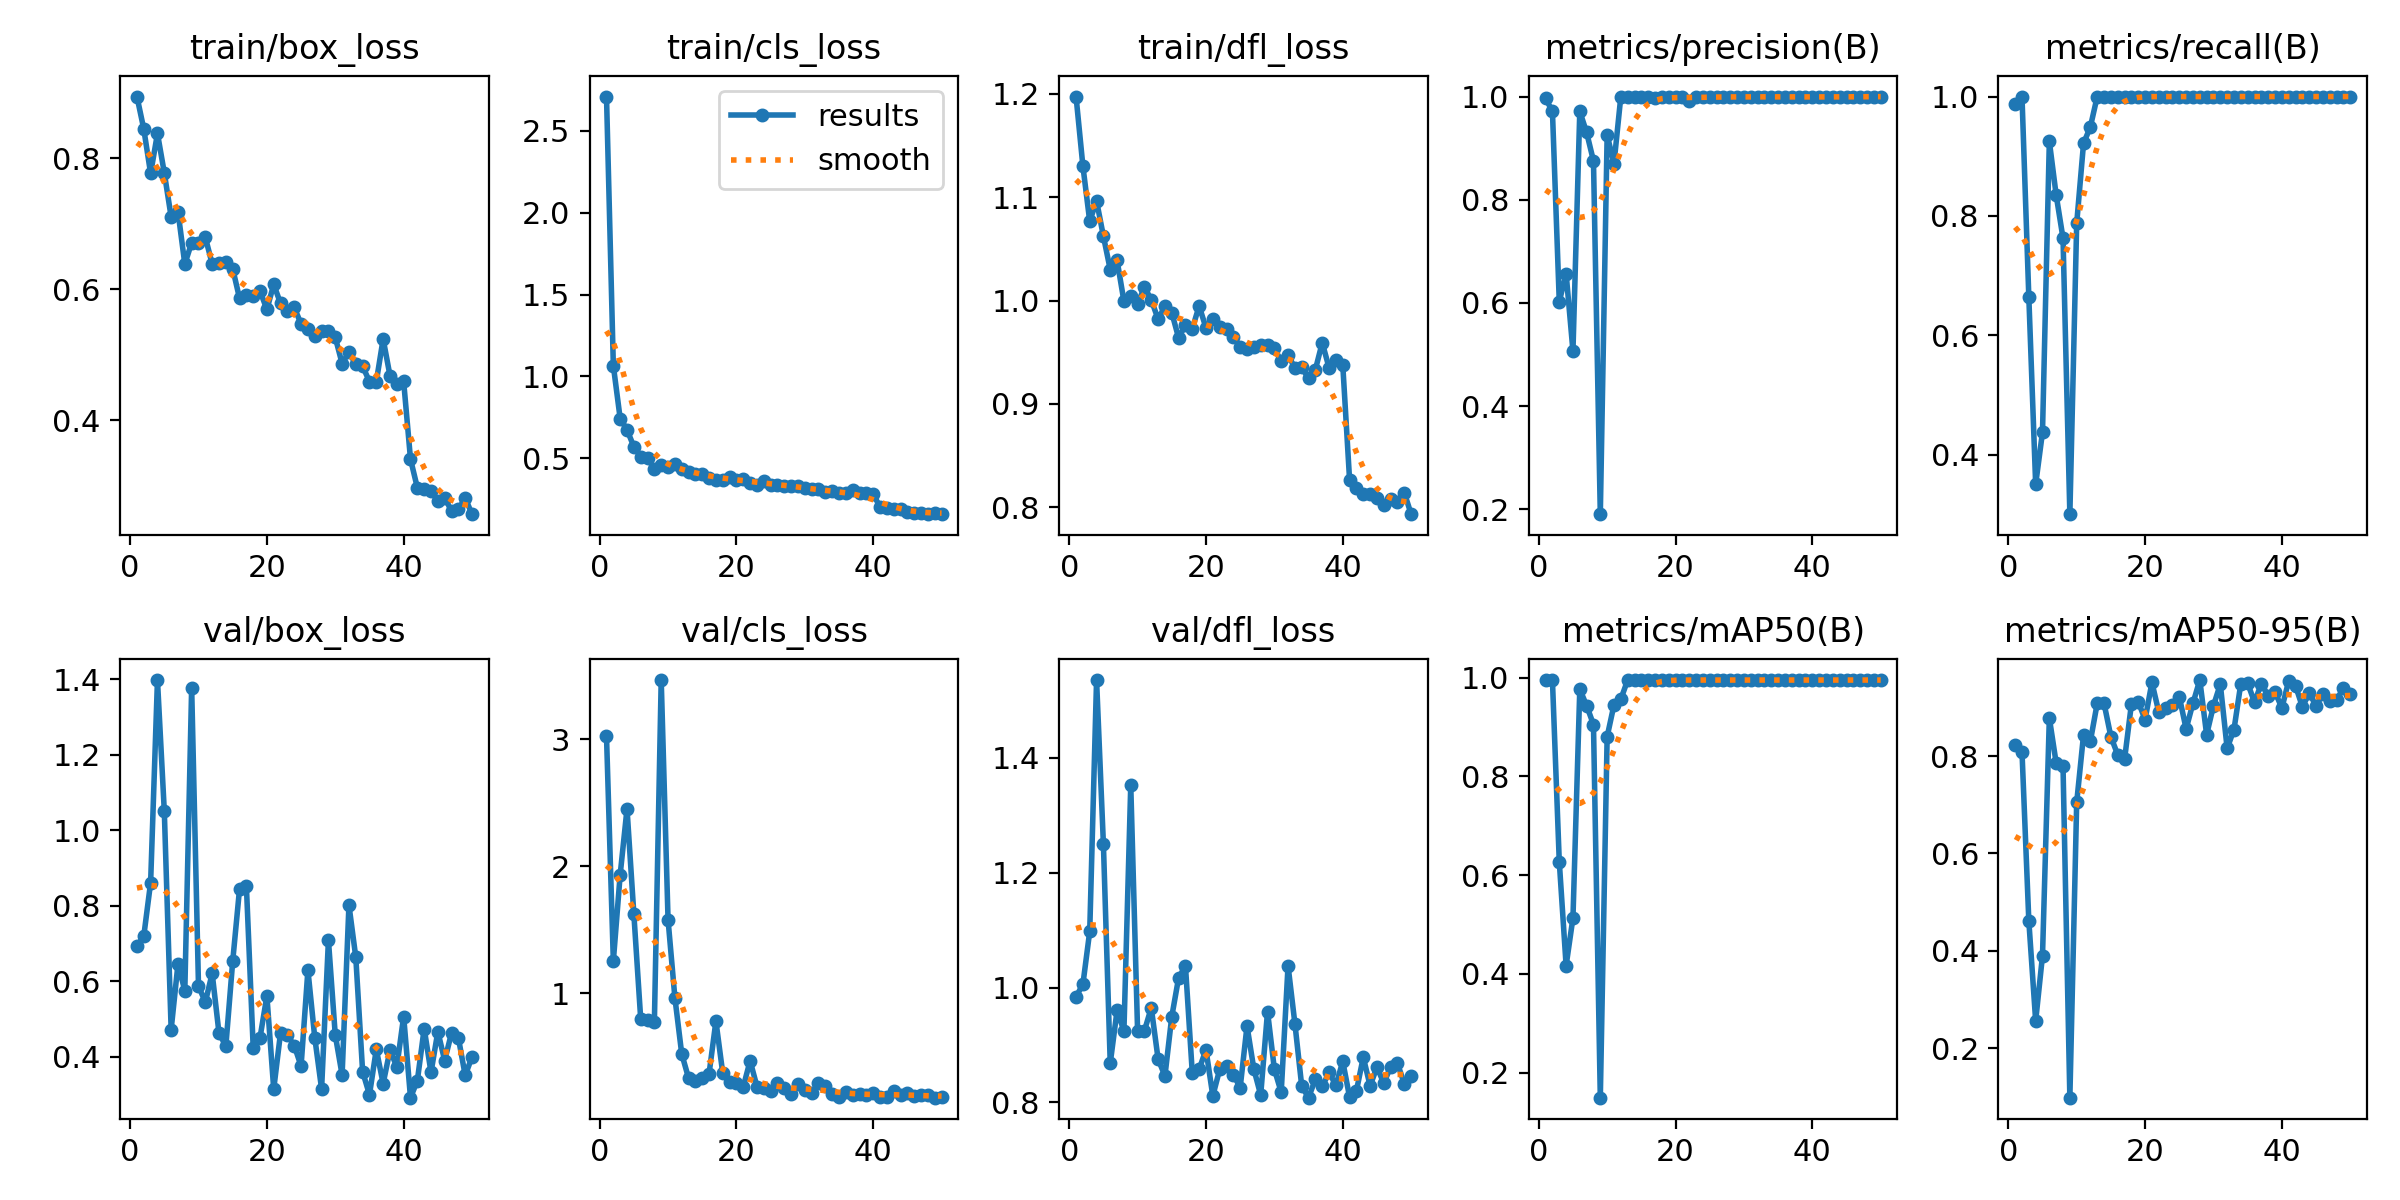

Ultralytics 8.4.183 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX A5000, 24112MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2806.1±709.1 MB/s, size: 67.7 KB)
val: Scanning /home/c-jaylavapie/cv/autonomous_parking/parking_area_yolo_dataset/valid/labels.cache... 80 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 80/80 12.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 3.7it/s 1.4s0.4s
                   all         80         80      0.999          1      0.995      0.957
Speed: 2.2ms preprocess, 2.6ms inference, 0.0ms loss, 4.0ms postprocess per image
Results saved to /home/c-jaylavapie/cv/autonomous_parking/parking_area_runs/validation


,Result
Precision,0.999318
Recall,1.000000
mAP@50,0.995000
mAP@50:95,0.957263


In [8]:
results_dir=RUNS_DIR/'yolo_training'; csv_path=results_dir/'results.csv'
if csv_path.exists(): display(pd.read_csv(csv_path).tail()); display(Image.open(results_dir/'results.png'))
trained_model=YOLO(str(BEST_WEIGHTS))
validation=trained_model.val(data=str(LOCAL_DATA_YAML),split='val',imgsz=IMG_SIZE,device=DEVICE,project=str(RUNS_DIR),name='validation',exist_ok=True,plots=True)
metrics={'Precision':float(validation.box.mp),'Recall':float(validation.box.mr),'mAP@50':float(validation.box.map50),'mAP@50:95':float(validation.box.map)}
display(pd.DataFrame([metrics]).T.rename(columns={0:'Result'}))

## 7. Test Predictions

The unseen test images are rendered as Original Image -> YOLO Prediction, with box, `parking_area`, and confidence. Detection success uses the configurable threshold of 0.50.

,Image,Detections,Max confidence,Success
0,parking_area_0000.jpg,1,0.934830,True
1,parking_area_0001.jpg,1,0.925613,True
2,parking_area_0002.jpg,1,0.926375,True
3,parking_area_0003.jpg,1,0.933196,True
4,parking_area_0004.jpg,1,0.946611,True
5,parking_area_0005.jpg,1,0.932794,True
6,parking_area_0006.jpg,1,0.927945,True
7,parking_area_0007.jpg,1,0.944080,True
8,parking_area_0008.jpg,1,0.943020,True
9,parking_area_0009.jpg,1,0.950348,True


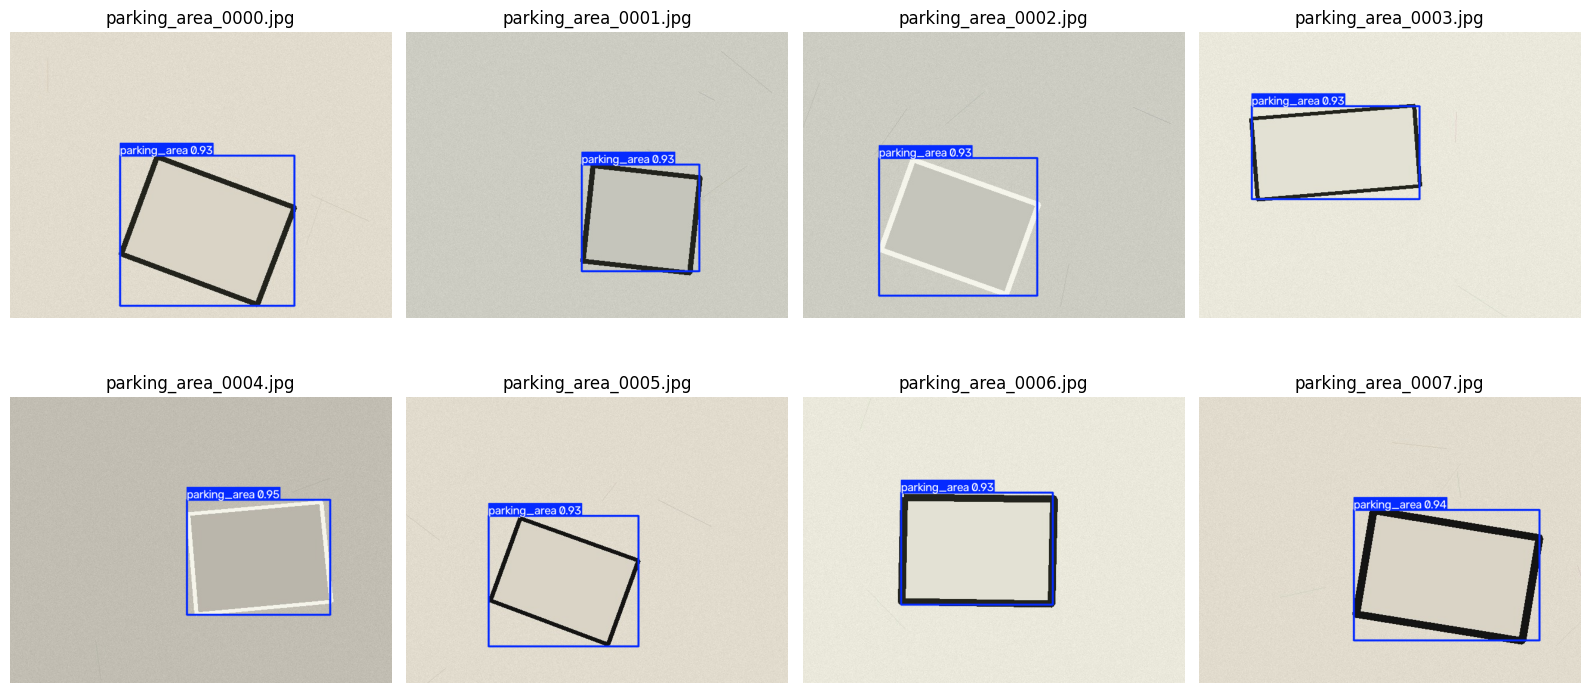

In [9]:
test_paths=image_files(DATASET_DIR/'test'/'images')
rows=[]
for path in test_paths:
    result=trained_model.predict(str(path),conf=CONFIDENCE_THRESHOLD,imgsz=IMG_SIZE,device=DEVICE,verbose=False)[0]; scores=result.boxes.conf.cpu().numpy().tolist() if result.boxes is not None else []
    rows.append({'Image':path.name,'Detections':len(scores),'Max confidence':max(scores,default=0.),'Success':bool(scores)})
test_summary=pd.DataFrame(rows); display(test_summary); detection_success_rate=100*test_summary.Success.mean(); average_confidence=test_summary.loc[test_summary.Success,'Max confidence'].mean()
fig,axes=plt.subplots(2,4,figsize=(16,8))
for ax,path in zip(axes.ravel(),test_paths[:8]): ax.imshow(cv2.cvtColor(trained_model.predict(str(path),conf=CONFIDENCE_THRESHOLD,verbose=False)[0].plot(),cv2.COLOR_BGR2RGB)); ax.set_title(path.name); ax.axis('off')
plt.tight_layout(); plt.show()

## 8. Parking Area Interpretation and Basic Decision Logic

The best detection supplies pixel center `(x,y)`, width, height, relative center, approximate orientation, and a target image-space parking position. A box cannot recover true floor-plane orientation; the longer image axis is reported as 0 or 90 degrees. No motor or navigation command is produced.

,Value
Decision,Parking Area Detected
Class,parking_area
Confidence,0.93483
"Center (x,y)","(330.3,333.7)"
Width (px),291.5
Height (px),252.3
Relative position,"(0.516,0.695)"
Approx. orientation,0
Target parking position,detected-area center


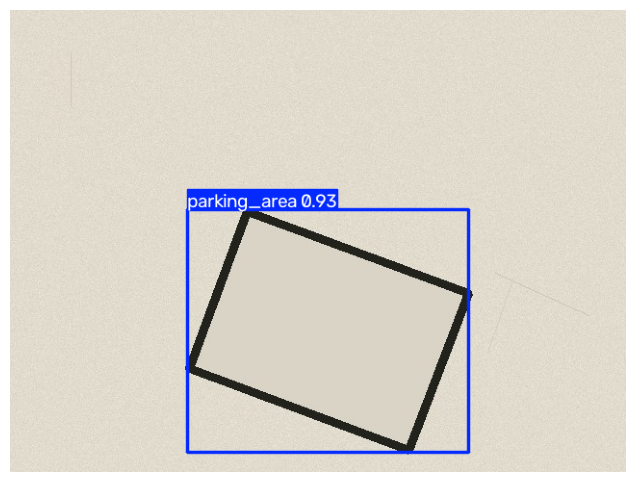

In [10]:
def interpret(result,shape,threshold=CONFIDENCE_THRESHOLD):
    if result.boxes is None or len(result.boxes)==0: return {'Decision':'Parking Area Not Detected'}
    i=int(result.boxes.conf.argmax()); x1,y1,x2,y2=result.boxes.xyxy[i].cpu().numpy(); score=float(result.boxes.conf[i]); h,w=shape[:2]; bw,bh=x2-x1,y2-y1; cx,cy=(x1+x2)/2,(y1+y2)/2
    return {'Decision':'Parking Area Detected' if score>=threshold else 'Parking Area Not Detected','Class':CLASS_NAMES[int(result.boxes.cls[i])],'Confidence':score,'Center (x,y)':f'({cx:.1f},{cy:.1f})','Width (px)':round(float(bw),1),'Height (px)':round(float(bh),1),'Relative position':f'({cx/w:.3f},{cy/h:.3f})','Approx. orientation':0 if bw>=bh else 90,'Target parking position':'detected-area center'}
result=trained_model.predict(str(test_paths[0]),conf=CONFIDENCE_THRESHOLD,verbose=False)[0]; display(pd.DataFrame([interpret(result,cv2.imread(str(test_paths[0])).shape)]).T.rename(columns={0:'Value'})); plt.figure(figsize=(9,6)); plt.imshow(cv2.cvtColor(result.plot(),cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

## 10. Results and Discussion

### Dataset Distribution
The inspection table above reports training, validation, and testing images, annotation files, dimensions, and image-label pairs.

### YOLO Evaluation
The evaluation table reports Precision, Recall, mAP@50, mAP@50:95, and test Detection Success Rate. Discuss false positives versus missed areas, confidence by angle/distance/lighting, box localization, and failed cases after running the model.

## 11. Limitations and Conclusion
A box is image-space geometry, not metric pose. Perspective, occlusion, lighting, tape contrast, camera calibration, and the coarse orientation estimate limit accuracy. More varied labels, calibration, segmentation/oriented boxes, and representative real-world tests are possible improvements. This notebook completes the requested vision pipeline without implementing autonomous movement or motor control.